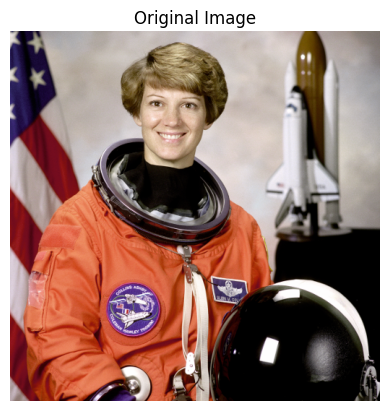

Shape: (512, 512, 3) | dtype: uint8


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


#Built-in sample image
from skimage import data
img_rgb = data.astronaut()                      # already in RGB order
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)

# OpenCV loads images as BGR, so convert to RGB for display
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()
print("Shape:", img_rgb.shape, "| dtype:", img_rgb.dtype)

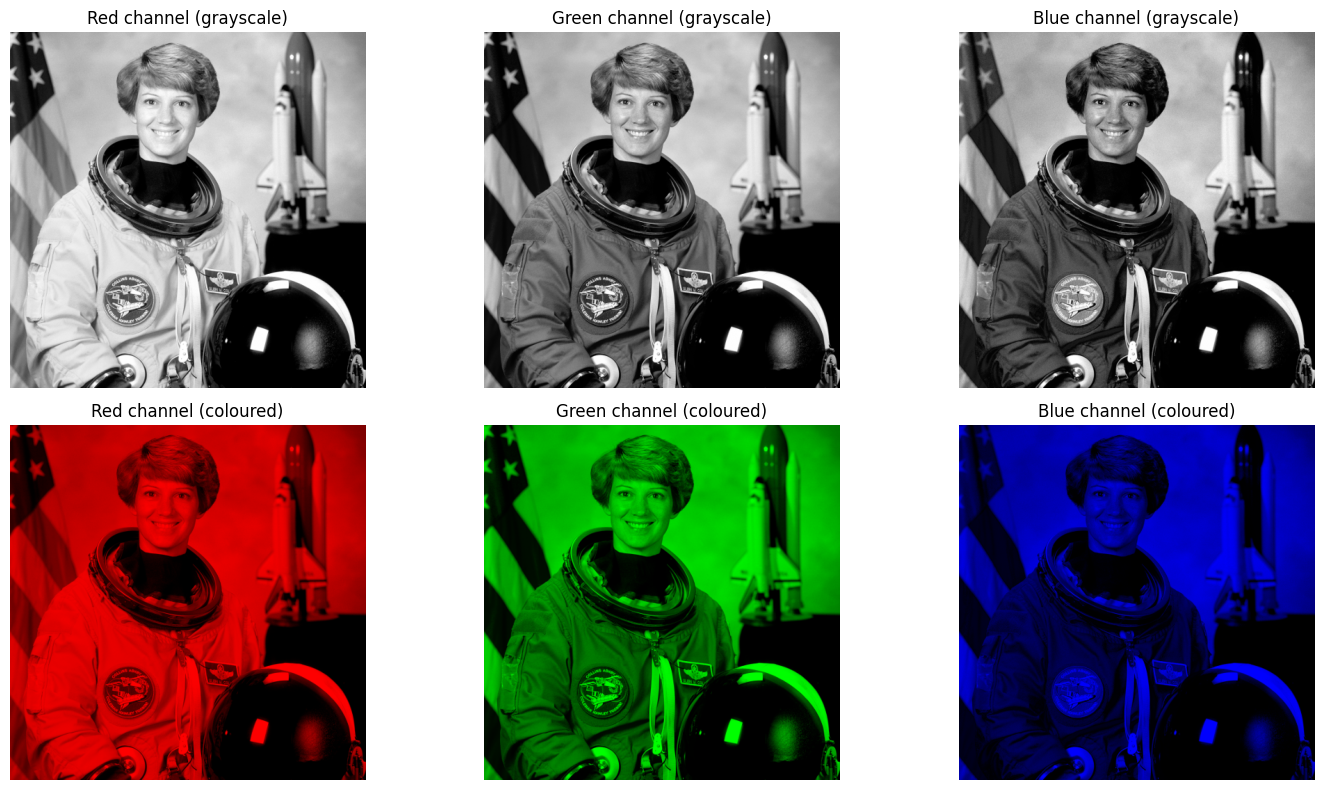

In [ ]:
# cv2.split on a BGR image returns B, G, R
b, g, r = cv2.split(img_bgr)

# Tint each channel in its own colour so it is easy to read
zeros = np.zeros_like(b)
red_img   = cv2.merge([zeros, zeros, r])   # BGR order
green_img = cv2.merge([zeros, g, zeros])
blue_img  = cv2.merge([b, zeros, zeros])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Row 1: grayscale view (brightness of each channel)
for ax, ch, name in zip(axes[0], [r, g, b], ["Red", "Green", "Blue"]):
    ax.imshow(ch, cmap="gray")
    ax.set_title(f"{name} channel (grayscale)")
    ax.axis("off")

# Row 2: colour-tinted view
for ax, im, name in zip(axes[1], [red_img, green_img, blue_img], ["Red", "Green", "Blue"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name} channel (coloured)")
    ax.axis("off")

plt.tight_layout()
plt.show()

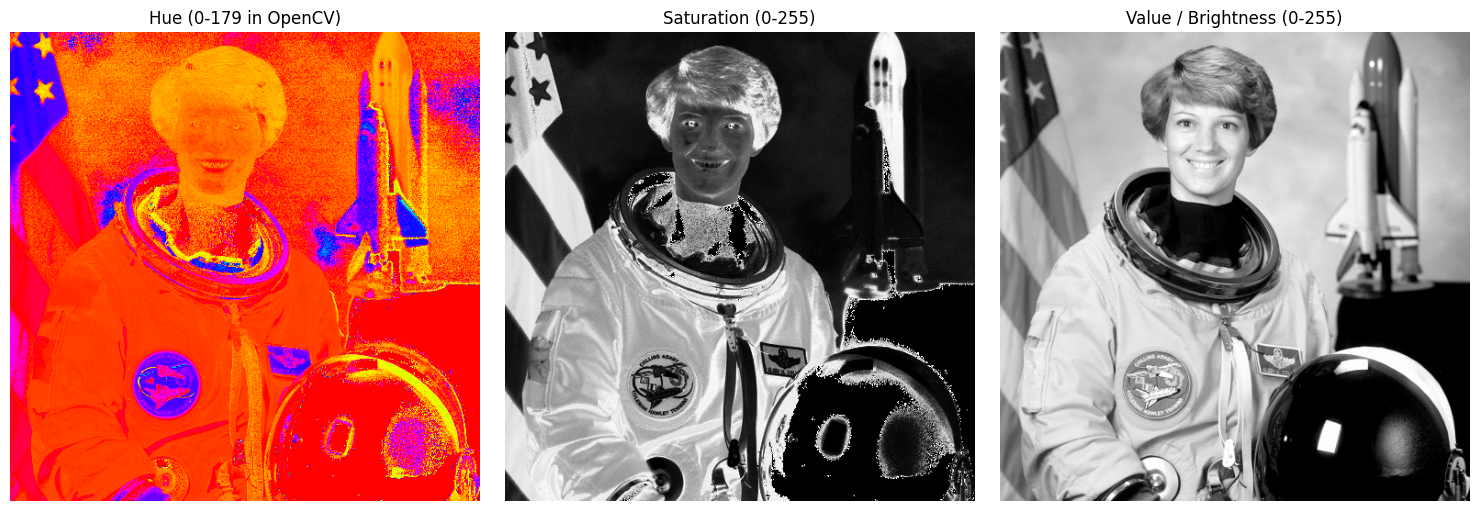

Hue range: 0 - 179
Saturation range: 0 - 255
Value range: 0 - 255


In [ ]:
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(img_hsv)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(h, cmap="hsv");  axes[0].set_title("Hue (0-179 in OpenCV)")
axes[1].imshow(s, cmap="gray"); axes[1].set_title("Saturation (0-255)")
axes[2].imshow(v, cmap="gray"); axes[2].set_title("Value / Brightness (0-255)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Hue range:", h.min(), "-", h.max())
print("Saturation range:", s.min(), "-", s.max())
print("Value range:", v.min(), "-", v.max())

HSV is often better than RGB for computer vision because it separates colour from brightness. In RGB, all three channels change when the lighting changes. The same red object in sunlight and in shadow has very different R, G and B values, so thresholds based on RGB break easily.

In HSV, Hue holds the colour type, Saturation holds its purity, and Value holds the brightness. When the lighting changes, mostly Value changes and Hue stays fairly stable. This gives better colour constancy, so you can detect an object by its hue range across bright and dim conditions. That is why HSV is widely used for colour-based tracking and segmentation.